In [1]:
import sys
import os
import pandas as pd

sys.path.append(os.path.abspath('..'))

from quinex_application.visualisation.quinex_visualisation import QuinexVisualisation

In [2]:
visualisation = QuinexVisualisation()

### **Import Results**

### **Efficiency**

In [3]:
df = pd.read_parquet("../data/visualisation_files/df_technologies.parquet")
efficiency = df[df["property_mapping"] == "Efficiency"]
print(efficiency["unit_normalized"].value_counts())
efficiency = efficiency[efficiency['unit_normalized'].apply(
    lambda lst: len(lst) == 1 and lst[0].get('unit_uri') == 'http://qudt.org/vocab/unit/PERCENT'
)]
efficiency["unit_normalized"].value_counts()

unit_normalized
[{'exponent': 1.0, 'text': '%', 'unit_uri': 'http://qudt.org/vocab/unit/PERCENT', 'year': None}]                                                                                                                                                                                                          14701
[{'exponent': None, 'text': None, 'unit_uri': 'http://qudt.org/vocab/unit/UNITLESS', 'year': None}]                                                                                                                                                                                                        2477
[{'exponent': 1.0, 'text': 'percent', 'unit_uri': 'http://qudt.org/vocab/unit/PERCENT', 'year': None}]                                                                                                                                                                                                       62
[{'exponent': 1.0, 'text': 'W/m2', 'unit_uri': 'http://qudt.org/vocab/un

unit_normalized
[{'exponent': 1.0, 'text': '%', 'unit_uri': 'http://qudt.org/vocab/unit/PERCENT', 'year': None}]          14701
[{'exponent': 1.0, 'text': 'percent', 'unit_uri': 'http://qudt.org/vocab/unit/PERCENT', 'year': None}]       62
Name: count, dtype: int64

In [4]:
efficiency = visualisation.convert_spatial(efficiency, spatial_col="spatial_scope_refined")
print(efficiency["entity_mapping"].value_counts())
efficiency = efficiency[efficiency["entity_mapping"] == "PV"]

entity_mapping
PV                             491
Bioenergy                      111
Wind                            77
Hydrogen                        73
Geothermal                      72
Coal                            60
Natural Gas                     46
Electrolyzer                    43
Battery                         27
Hybrid Energy System            26
Hydropower                      14
CCS                             10
Lead Acid Battery               10
Nuclear                          9
Lithium-Ion Battery              8
Offshore Wind                    4
Onshore Wind                     3
Green Hydrogen                   3
Liquefied Natural Gas (LNG)      2
DACCS                            1
Name: count, dtype: int64


#### **LCOE**

In [5]:
cost_lcoe = pd.read_excel("../data/visualisation_files/unit_converted/df_technologies_lcoe2024.xlsx")
cost_lcoe = cost_lcoe[cost_lcoe["entity_base_mapping"].isin(['PV'])]

In [6]:
cost_lcoe = visualisation.convert_spatial(cost_lcoe, spatial_col="spatial_scope_refined")
print(cost_lcoe["entity_base_mapping"].value_counts())

entity_base_mapping
PV    606
Name: count, dtype: int64


In [7]:
cost_lcoe = cost_lcoe[cost_lcoe["value_converted"] < 0.51]
len(cost_lcoe)

525

### **Cap Factor**

In [8]:
# df = pd.read_parquet("../data/visualisation_files/df_technologies.parquet")
# cap_factor_raw = df[df["property_mapping"] == "Capacity Factor"]
# percent = cap_factor_raw[
#     cap_factor_raw['unit_normalized'].apply(
#         lambda lst: len(lst) == 1 and lst[0].get('unit_uri') == 'http://qudt.org/vocab/unit/PERCENT'
#     )
# ]

# unitless = cap_factor_raw[
#     cap_factor_raw['unit_normalized'].apply(
#         lambda lst: len(lst) == 1 and lst[0].get('unit_uri') == 'http://qudt.org/vocab/unit/UNITLESS'
#     )
# ]

# # nur Werte zwischen 0 und 1 behalten
# unitless = unitless[unitless['value_normalized'].between(0, 1)]

# # auf Prozent skalieren
# unitless['value_normalized'] = unitless['value_normalized'] * 100

# # zusammenführen
# cap_factor = pd.concat([percent, unitless], ignore_index=True)
# cap_factor["unit_normalized"].value_counts()

In [9]:
# cap_factor['entity_mapping'] = cap_factor['entity_mapping'].replace({
#     'Onshore Wind': 'Wind'
# })
# cap_factor = cap_factor[cap_factor["entity_mapping"].isin(["Wind"])]

In [10]:
# cap_factor = visualisation.convert_spatial(cap_factor, spatial_col="spatial_scope_refined")
# print(cap_factor["entity_mapping"].value_counts())

In [11]:
# cap_factor = cap_factor[(cap_factor["value_normalized"] > 10) & (cap_factor["value_normalized"] < 60)]
# len(cap_factor)

### **Visualize Results**

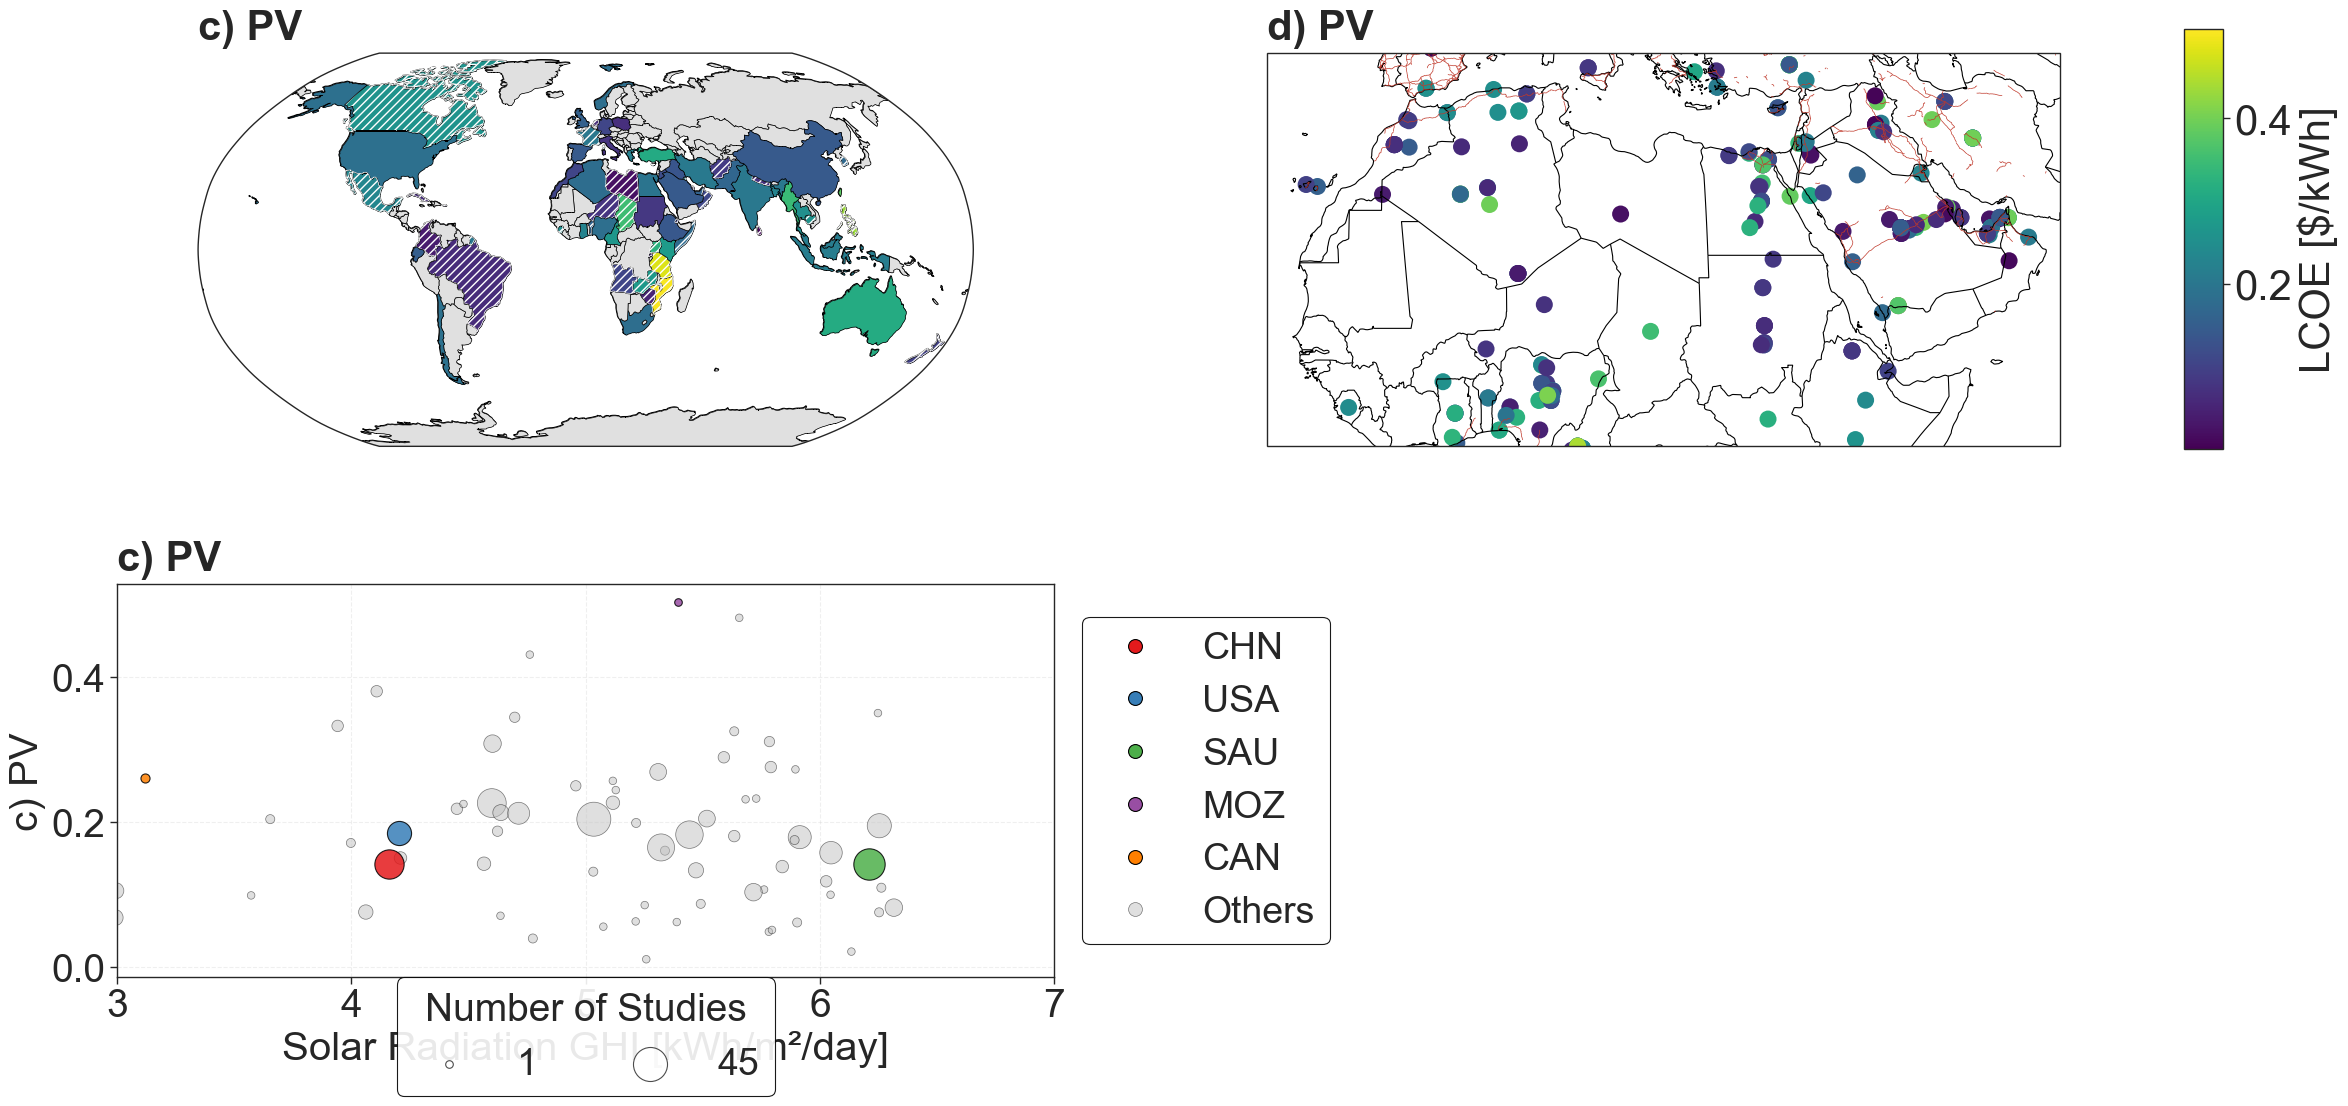

In [12]:
datasets = [
    {
    'df': cost_lcoe,
    'value_column': 'value_converted',
    'title': 'c) PV',
    'plot_mode': 'choropleth',
    'min_datapoints': 3,
    },
    {
    'df': cost_lcoe,
    'value_column': 'value_converted',
    'title': 'd) PV',
    'plot_mode': 'points',
    'spatial_extent': [-20, 60, 5, 40],
    'show_roads': 'highway',
    },
    {
    'df': cost_lcoe[cost_lcoe["value_converted"] < 0.85],
    'value_column': 'value_converted',
    'title': 'c) PV',
    'plot_mode': 'size',
    'ghi_data_path': "../data/visualisation_files/country_GHI_mean.xlsx",
    'highlight_countries': ['CHN', 'USA', 'SAU', 'MOZ', 'CAN'],
    'x_range': [3,7],
    #'min_datapoints': 10,
    #'show_regression': True,
    },
]

fig, data_tables = visualisation.plot_multiple_datasets_on_world(
    datasets,
    colorbar_title="LCOE [$/kWh]",
    figsize=(26, 12),
    jitter_strength=0,
    default_point_size=150,
    font_size=30,
)

fig.savefig("../data/figures/results/spatial/lcoe_pv.pdf", bbox_inches='tight')

In [13]:
data_tables

{'c) PV':    country  avg_value  n_datapoints       ghi  bubble_size
 0      AFG   0.087473             2  5.491130    42.954545
 1      AGO   0.107180             1  5.761307    30.000000
 2      ARE   0.157959            19  6.047002   263.181818
 3      AUS   0.311129             3  5.784267    55.909091
 4      BEN   0.160744             2  5.338404    42.954545
 ..     ...        ...           ...       ...          ...
 69     UGA   0.325300             2  5.634042    42.954545
 70     USA   0.185530            22  4.202620   302.045455
 71     ZAF   0.180842             4  5.633909    68.863636
 72     ZMB   0.272821             1  5.895256    30.000000
 73     ZWE   0.051475             1  5.795048    30.000000
 
 [74 rows x 5 columns]}

In [14]:
# Display scatter data (avg_value, n_datapoints, ghi per country)
for title, df_table in data_tables.items():
    print(f"\n--- {title} ---")
    display(df_table.sort_values("n_datapoints", ascending=False).head(20))


--- c) PV ---


,country,avg_value,n_datapoints,ghi,bubble_size
28,IND,0.204120,45,5.034712,600.000000
59,SAU,0.142630,38,6.207105,509.318182
9,CHN,0.141814,33,4.159152,444.545455
5,BGD,0.226365,32,4.599339,431.590909
47,NGA,0.182874,29,5.442919,392.727273
53,PAK,0.165206,28,5.321666,379.772727
18,EGY,0.195143,22,6.253116,302.045455
70,USA,0.185530,22,4.202620,302.045455
17,DZA,0.179380,20,5.913517,276.136364
2,ARE,0.157959,19,6.047002,263.181818


In [15]:
df_table[df_table["country"] == "TZA"]

,country,avg_value,n_datapoints,ghi,bubble_size
68,TZA,0.481746,1,5.655396,30.0


### **Investigate Results**

In [16]:
df = pd.read_excel("../data/visualisation_files/country_GHI_mean.xlsx")

In [17]:
df[df["Country"] == "Mali"]

,Country,GHI_mean
97,Mali,6.013666
